# DATA 5100 - Foundations of Data Science -Education Project

## Introduction
The purpose of this project is to determine if socioeconomic status predicts ACT scores. Publically available data was used to gather information about specific indicators of socioeconomic status and school information, including ACT scores. Regression analysis was used to determine which specific socioeconomic indicators predicted ACT scores and how influential each of those indicators were on ACT scores 

### Import necessary libraries

In [2]:
# import pandas, numpy, matplotlib, and seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# set plotting style
sns.set_style("whitegrid")

### Load  original/raw data sets

In [6]:
edgap = pd.read_excel('https://raw.githubusercontent.com/kderosia31/education/main/data/EdGap_data.xlsx',
                      dtype={'NCESSCH School ID': object}
                     )
school_information = pd.read_csv("C:/Users/kderosia/OneDrive - Seattle University/Desktop/Python/Data 5100 - Foundations of Data Science/Projects/education/data/ccd_sch_029_1617_w_1a_11212017.csv",
                                 encoding = "unicode_escape"
                                )

C:\Users\kderosia\AppData\Local\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\kderosia\AppData\Local\Temp\ipykernel_37944\4117425058.py:4: DtypeWarning: Columns (0: STATE_AGENCY_NO, 1: LEAID, 2: MSTREET2, 3: MSTREET3, 4: MZIP, 5: MZIP4, 6: LSTREET2, 7: LSTREET3, 8: LZIP, 9: LZIP4, 10: SY_STATUS, 11: UPDATED_STATUS, 12: SCH_TYPE, 13: CHARTAUTH1, 14: CHARTAUTH2, 15: CHARTAUTHN2) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information = pd.read_csv("C:/Users/kderosia/OneDrive - Seattle University/Desktop/Python/Data 5100 - Foundations of Data Science/Projects/education/data/ccd_sch_029_1617_w_1a_11212017.csv",


Brief data check

In [7]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [9]:
#Set default head display to show max columns
pd.set_option('display.max_columns', None)
#Check data set
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


Check data types and null values

In [10]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [11]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

### Checking to see if data is suitable to answer the question by visualzing relationships within the data set

<function matplotlib.pyplot.show(close=None, block=None)>

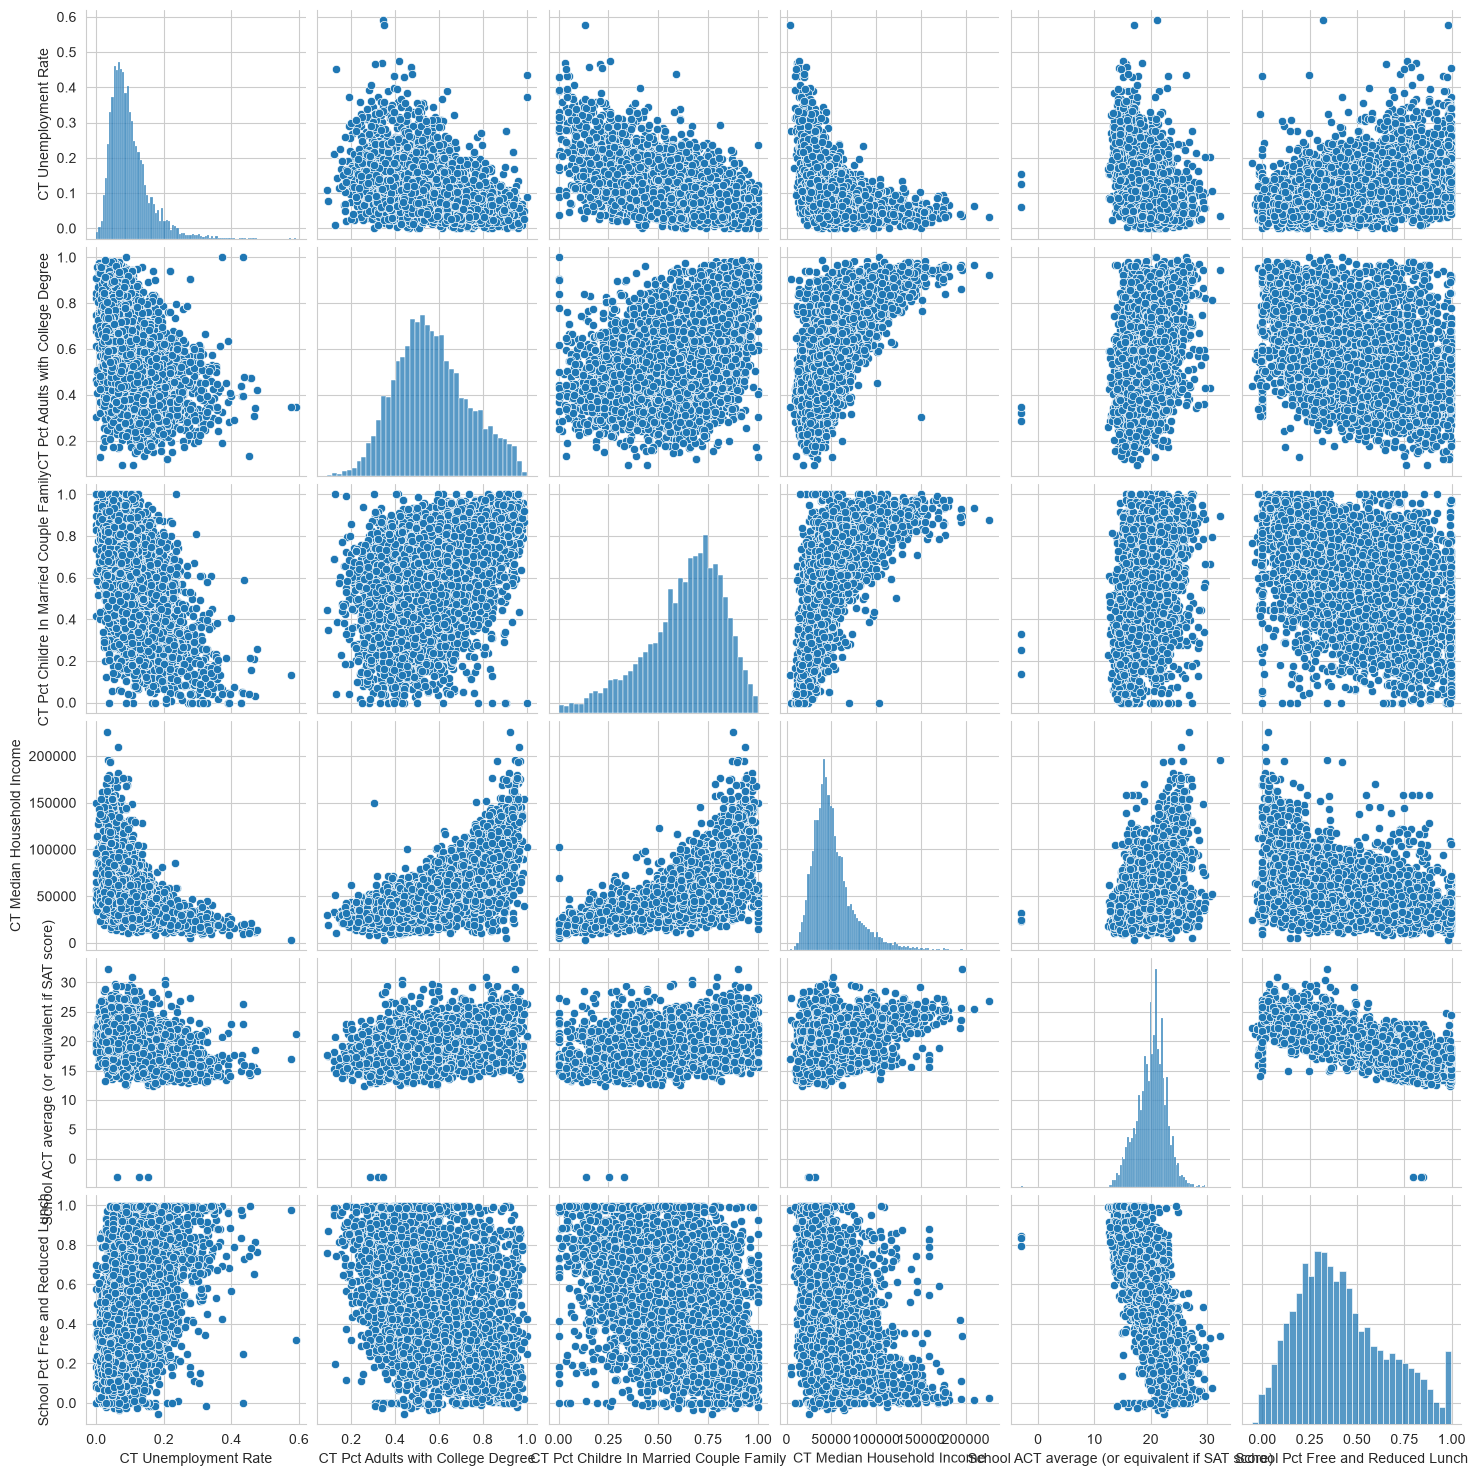

In [12]:
# create a pair plot
sns.pairplot(
    edgap.drop(columns='NCESSCH School ID')
);
plt.show

### Adding regression lines and formatting to the pair plots to improve clarity

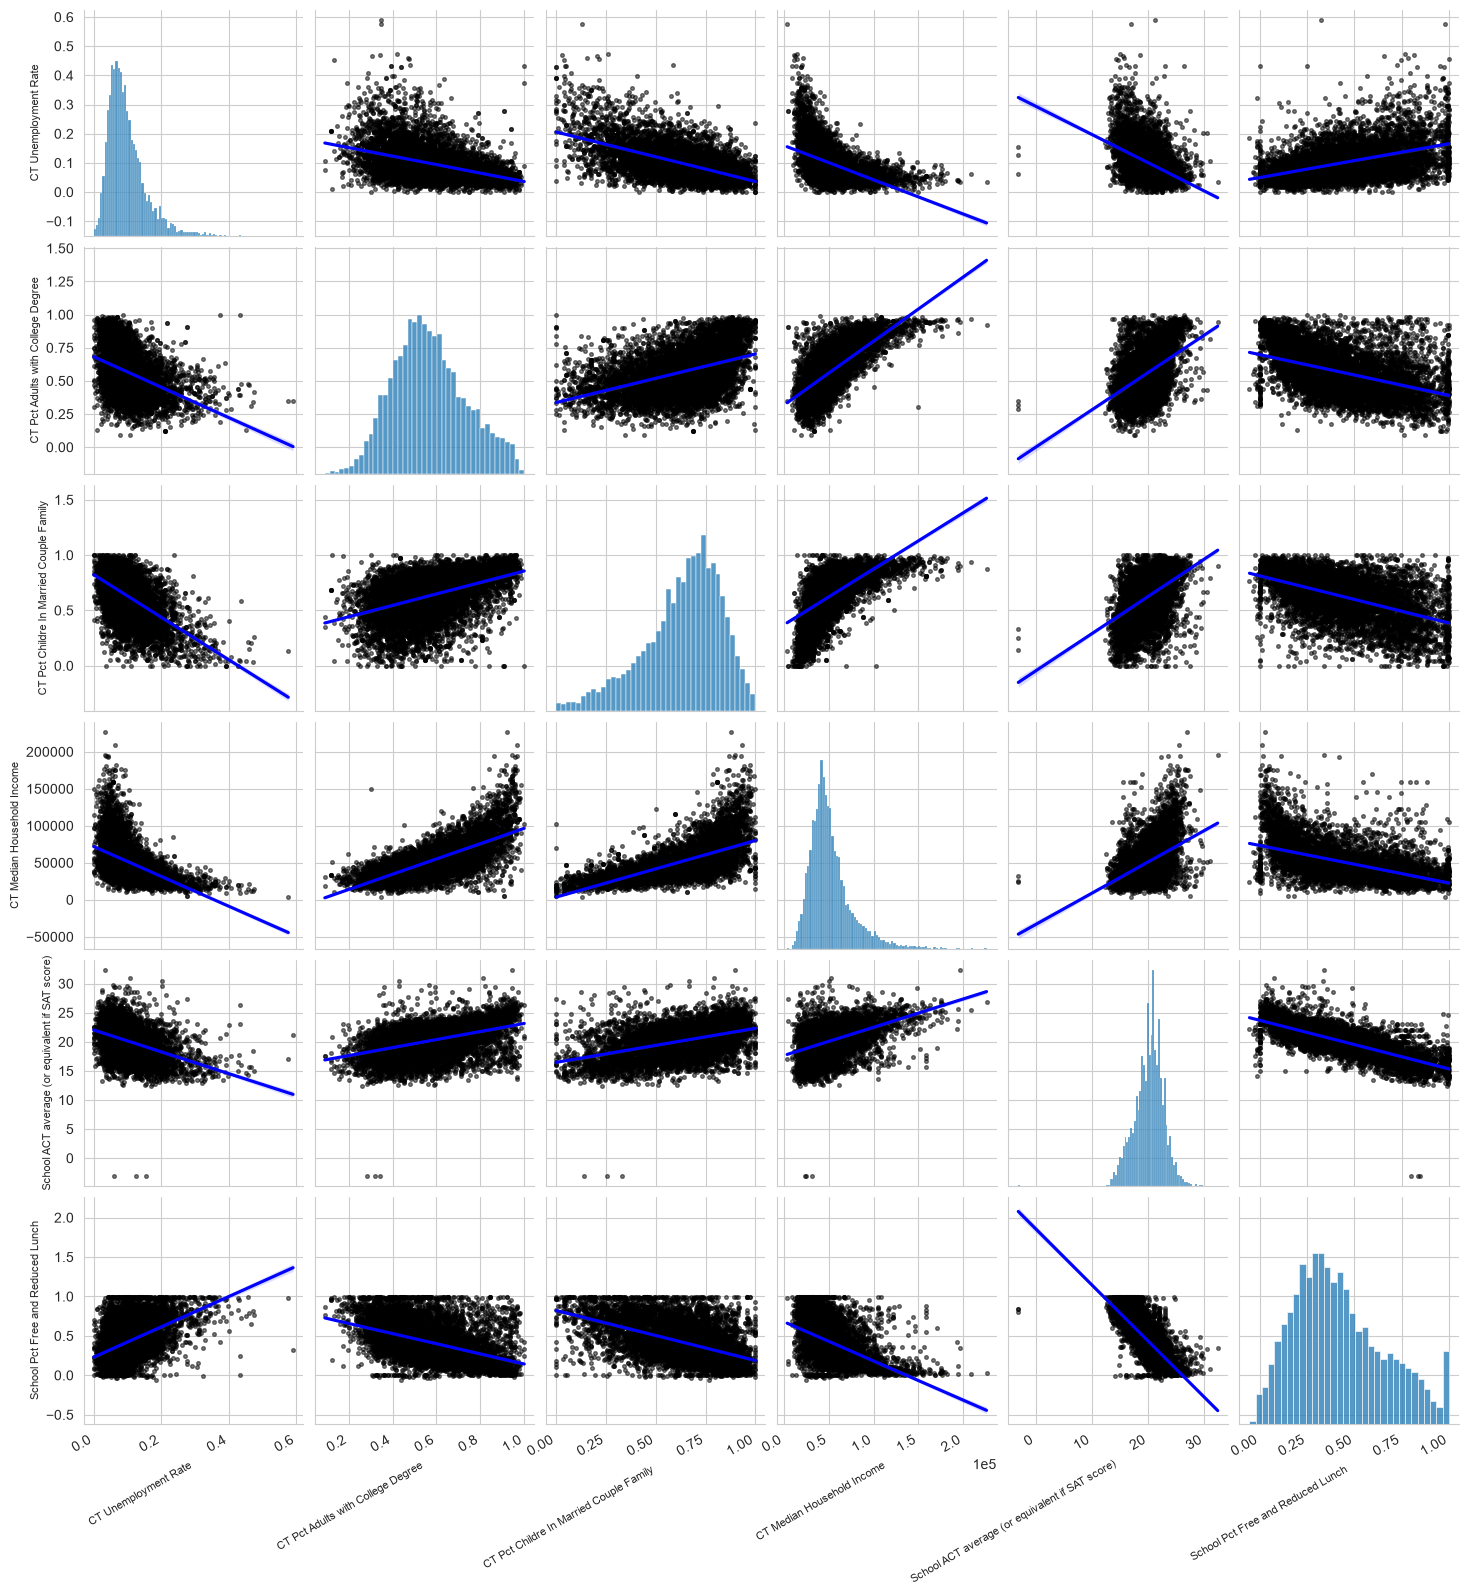

In [13]:
fig = sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"),
    kind = "reg",
    plot_kws={
        "line_kws": {"color": "blue"},
        "scatter_kws": {"alpha": 0.5, "color": "k", "s": 7},
            },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

Plot the single row we are interested in, the ACT scores

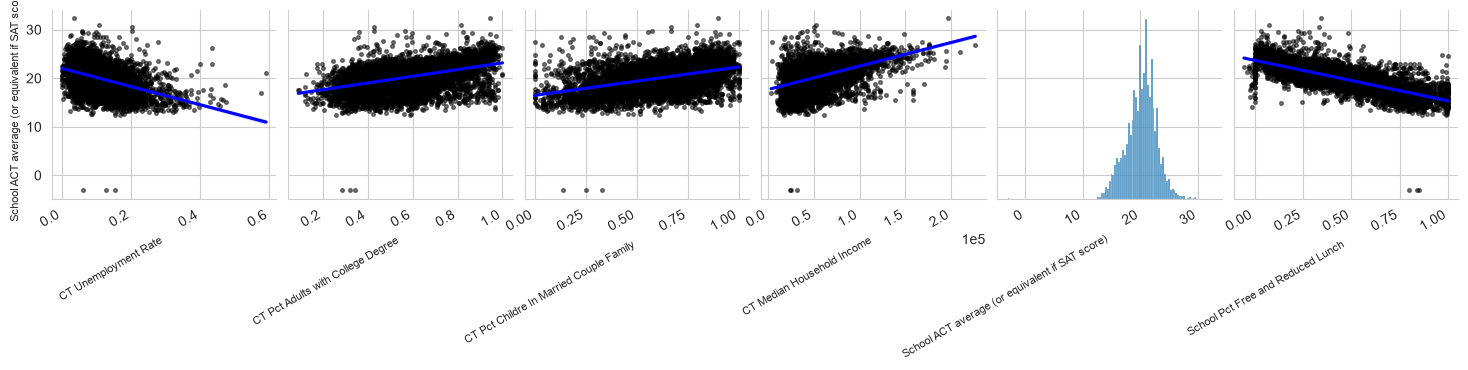

In [14]:
fig = sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"),
    y_vars=['School ACT average (or equivalent if SAT score)'],
    kind = "reg",
    plot_kws={
        "line_kws": {"color": "blue"},
        "scatter_kws": {"alpha": 0.5, "color": "k", "s": 7},
            },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

It looks like some relationships exist, but there is also some bad data that will likely need to be cleaned

# Selecting relevant subsets and renaming columns

In [15]:
# Update school info df to include only selected columns
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
    ]
# check new df
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


Reaname columns to follow best practices

In [17]:
edgap = edgap.rename(
    columns = {'NCESSCH School ID': "id",
               'CT Pct Adults with College Degree': 'percent_college',
               'CT Unemployment Rate': 'rate_unemployment',
               'CT Pct Childre In Married Couple Family': "percent_married",
               "CT Median Household Income": "median_income",
               "School ACT average (or equivalent if SAT score)": "average_act",
               "School Pct Free and Reduced Lunch": "percent_lunch",
              }
)

# Check
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [18]:
school_information = school_information.rename(
    columns = {'SCHOOL_YEAR': "year",
               'NCESSCH': "id",
               'LSTATE': 'state',
               'LZIP': 'zip_code',
               'SCH_TYPE_TEXT': "school_type",
               "LEVEL": "school_level",
               "CHARTER_TEXT": "charter"
              }
)

# Check
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


# Joining the two data frames

In [19]:
# Make id data types match between dfs
school_information['id'] = school_information['id'].astype('object')
# Check
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  str   
 1   id            102181 non-null  object
 2   state         102183 non-null  str   
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  str   
 5   school_level  102179 non-null  str   
 6   charter       102179 non-null  str   
dtypes: object(2), str(5)
memory usage: 9.0+ MB


In [21]:
# Join data frames
df = edgap.merge(
    school_information,
    how = 'left',
    on = 'id'
)

# Check
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   str    
 11  school_level       7898 non-null   str    
 12  charter            7898 non-null   str    
dtypes: float64(6), object(2), str(5)
memory usage: 1.0+ MB


# Quality Control: Looking for missing or out of range values that will impact the findings

In [22]:
#qucik check of data values
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


df contains negative values in ACT and percent columns. These are out of range

Set out-of-range values to Nan

In [23]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan

df.loc[df['average_act'] < 1, 'average_act'] = np.nan

Check the types, levels, and charter status of schools

In [24]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [25]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [26]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

Keep only the high schools

In [27]:
df = df.loc[df['school_level'] == 'High']

Check for duplicated rows

In [28]:
df.duplicated().sum()

np.int64(0)

## Identify missing values

In [29]:
# Determine how many values are missing in each variable
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


Identify what percentage of values are missing

In [31]:
percent_missing = df.isna().mean().round(4) * 100
percent_missing.to_frame(name='Percent Mising Values')

,Percent Mising Values
id,0.00
rate_unemployment,0.17
percent_college,0.15
percent_married,0.28
median_income,0.22
average_act,0.04
percent_lunch,0.28
year,0.00
state,0.00
zip_code,0.00


Check what states we have data from

In [35]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [34]:
df['state'].nunique()

20

## Plot whcih states we have data from on a map

In [36]:
import plotly.offline as po
import plotly.graph_objs as pg

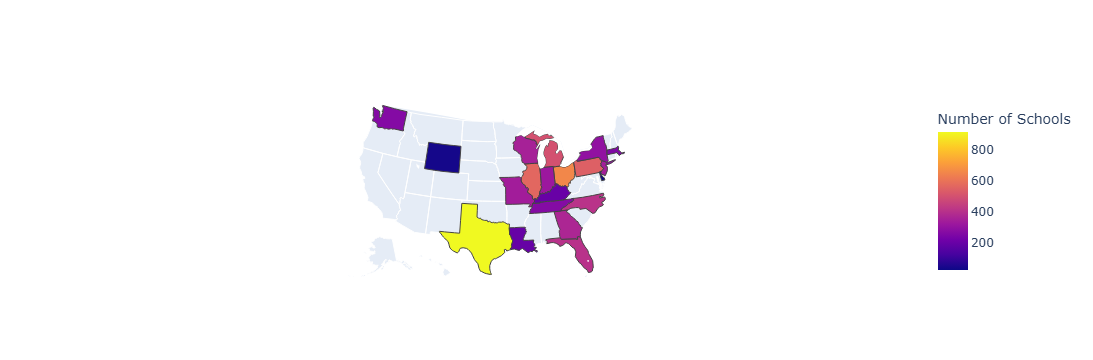

In [37]:
layout = dict(
    geo = {"scope": "usa"}, coloraxis_colorbar = dict(title="Number of Schools")
)

data = dict(
    type="choropleth",
    locations = df['state'].value_counts().index,
    locationmode="USA-states",
    z=df["state"].value_counts().values,
    coloraxis="coloraxis",
)

x = pg.Figure(data=[data], layout = layout)

po.iplot(x)

Drop rows where average ACT score is missing

In [39]:
df = df.dropna(subset=['average_act'])

In [40]:
df.isna().sum().to_frame(name="Number of Missing Values")

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


# Impute missing data and export the clean data set

define predictor variables to be rate_unemployment, percent_colege, percent_married, median_income, percent_lunch, state, and charter

In [42]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

Use iterative imputer to replace missing values in the columns corresponding to predictor variables in analysis

In [4]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [44]:
imputer = IterativeImputer()

Fit imputer using the numerical predictor variables

In [45]:
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


imputer.fit(df.loc[:, numerical_predictors])

Impute the missing values in the training data

In [47]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

Check for missing values

In [48]:
df.isna().sum().to_frame(name="Number of Missing Values")

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


# Exporting the clean df

In [49]:
df.to_csv(
    "education_clean.csv",
    encoding= 'utf-8-sig',
    index = False
)

# Exploratory Data Analysis

In [3]:
# Import libraries
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

### Examine distributions and relationships

<function matplotlib.pyplot.show(close=None, block=None)>

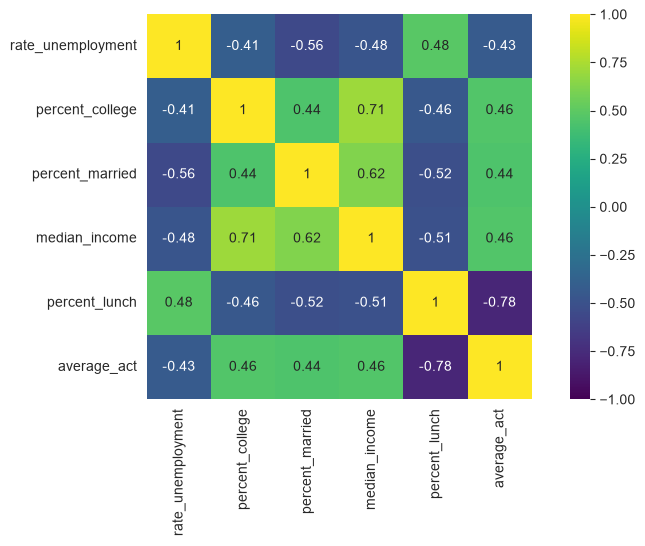

In [22]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()
corr_matrix = df[numerical_predictors+ ["average_act"]].corr()
plt.figure(figsize=(10,5))
sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap="viridis"
)
plt.show

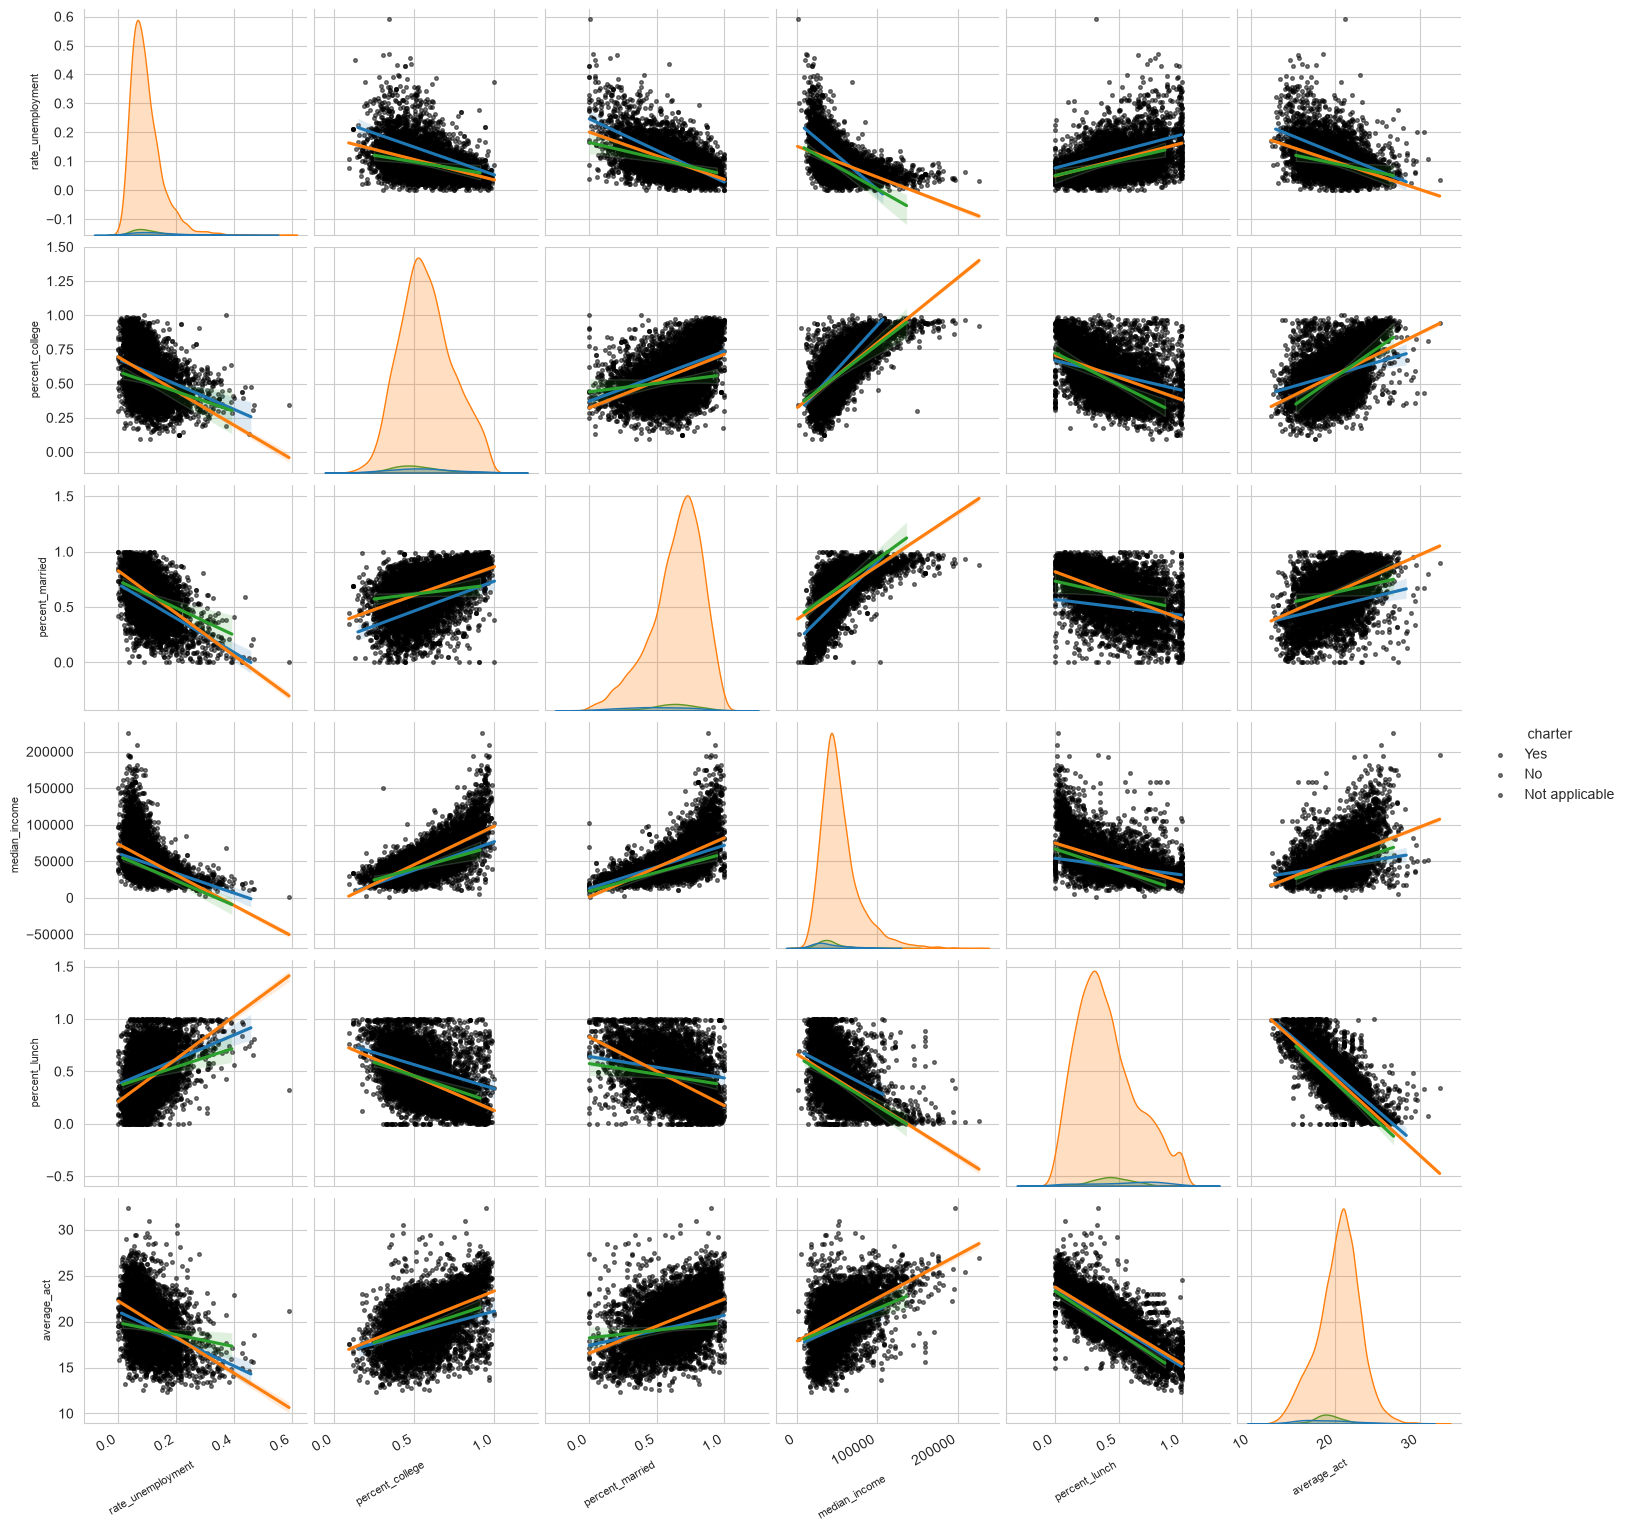

In [25]:
fig = sns.pairplot(
    data = df,
    vars=numerical_predictors + ['average_act'],
    hue='charter',
    kind='reg',
    plot_kws={'scatter_kws': {"alpha": 0.5, "color": "k","s": 7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation = 30, ha="right"),
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)

    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

plt.show()

### Identify outliers

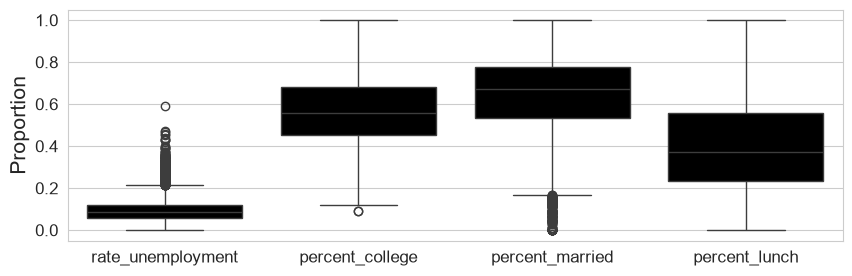

In [26]:
plt.figure(figsize=(10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data=df[fractions], color='k')

plt.ylabel('Proportion', fontsize=15)
plt.tick_params(labelsize=12)
plt.show()

Based on the above boxplot, there are some outliers in rate_unemployment and percent_married, but they don't seem so far out of range

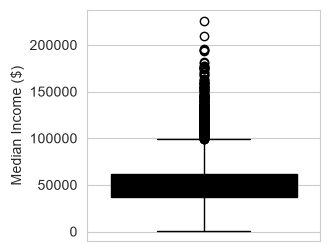

In [27]:
plt.figure(figsize=(3,3))

sns.boxplot(data=df, y = 'median_income', color = 'k')
plt.ylabel('Median Income ($)')
plt.show()

# Modeling
## Note: If you are interested in only the results, there is no need to load original data frames. The new data frame created above is already cleaned and can be used from here

In [5]:
# Load clean data
df = pd.read_csv("C:/Users/kderosia/OneDrive - Seattle University/Desktop/Python/Data 5100 - Foundations of Data Science/Projects/education/data/education_clean.csv")

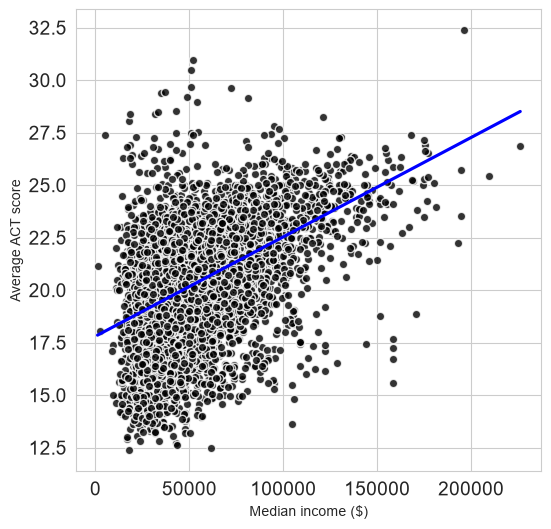

In [7]:
plt.figure(figsize=(6,6))

sns.regplot(data = df,
            x='median_income',
            y='average_act',
            color = 'blue',
            ci = False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths':1})

##add axis labels
plt.xlabel('Median income ($)')
plt.ylabel('Average ACT score')
plt.tick_params(labelsize=14)

## Fit the SLR model and check its summary

In [10]:
model_median_income = smf.ols(formula='average_act ~ median_income', data = df).fit()

In [11]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:53:51   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

## Assessing model fit numerically

In [12]:
# extract r squared
model_median_income.rsquared

np.float64(0.21118648979300758)

In [28]:
y_hat = model_median_income.predict()
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(2.228)

In [29]:
mean_absolute_error(df['average_act'], y_hat)

1.7129386980688568

## Assessing model fit visually

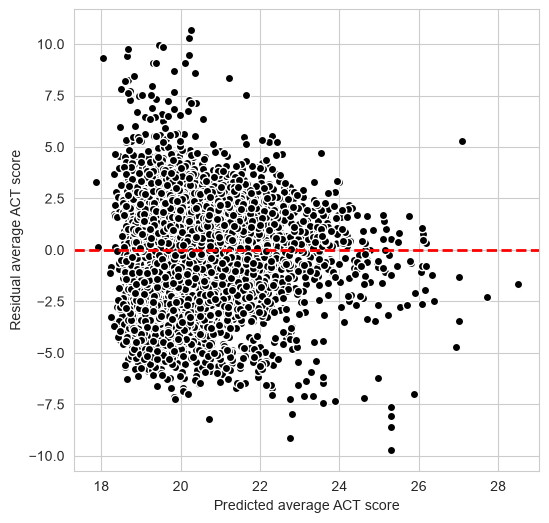

In [31]:
plt.figure(figsize=(6,6,))

plt.plot(y_hat, model_median_income.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score')
plt.ylabel('Residual average ACT score')

plt.show()

## Creating new models and plots since residuals don't appear normally distributed

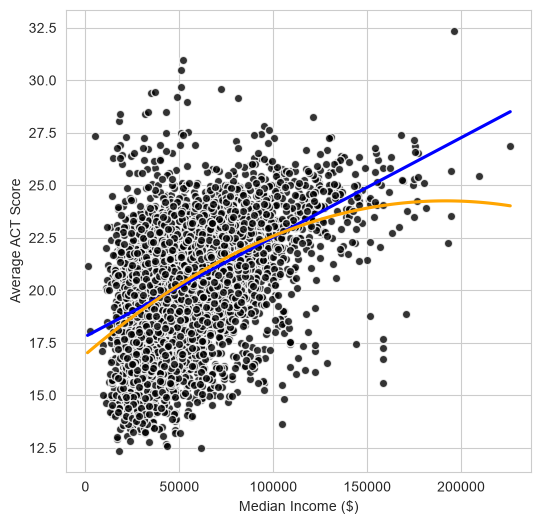

In [35]:
plt.figure(figsize=(6,6))

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            color = 'blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths':1})

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            order = 2,
            color = 'orange',
            ci=False,
            scatter=False)

plt.xlabel('Median Income ($)')
plt.ylabel('Average ACT Score')

plt.show()

The quadratic model may fit slightly better. Fit the model and check numerical values

In [36]:
model_median_income2 = smf.ols(
    formula = 'average_act ~ median_income + I(median_income**2)',
    data = df).fit()

In [37]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:39:50   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

Assessing model significance

In [38]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

In [39]:
#ESS F Test to compare reduced model and full model
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,35505.105960,1.0,359.906834,73.227974,1.395848e-17


Comparing quadratic model with reduced model

In [40]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.697238925790435

In [41]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.7129386980688568

The quadratic model may be slightly better, but probably not worth complicating the model

## Fitting MLR Models

## Full model

In [42]:
model = smf.ols(
    formula='average_act~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data=df).fit()

In [44]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:46:32   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6972      0.13

### Residual plot to assess model fit

In [47]:
y_hat = model.predict()

numpy.ndarray

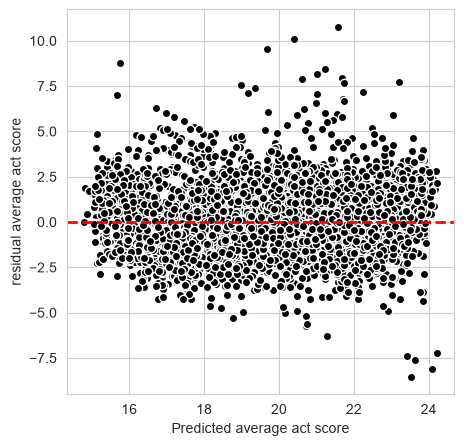

In [48]:
plt.figure(figsize=(5,5))

plt.plot(y_hat, model.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average act score')
plt.ylabel('residual average act score')

plt.show()

Residual plot looks good

In [49]:
mean_absolute_error(df['average_act'], model.predict())

1.145330478888391

Lower error than SLR model

## Reduced Model

In [7]:
model_reduce = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df).fit()

In [8]:
print(model_reduce.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:44:10   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

The model above explains 62.8% of the variance in ACT scores. That is pretty good!

### Graphical assessment of model fit

In [52]:
y_hat = model_reduce.predict()

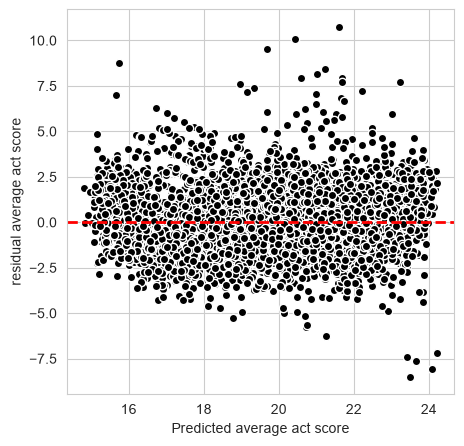

In [54]:
plt.figure(figsize=(5,5))

plt.plot(y_hat, model_reduce.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average act score')
plt.ylabel('residual average act score')

plt.show()

Residual plot still looks good

In [56]:
mean_absolute_error(df['average_act'], model_reduce.predict())

1.1454832950346459

Compare full and reduced models

In [57]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduce.predict())

r2_full = model.rsquared
r2_reduced = model_reduce.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
              'R-squared': [r2_full, r2_reduced]},
             index = ["full model", "reduced model"]).round(4)

,Mean Absolute Error,R-squared
full model,1.1453,0.6280
reduced model,1.1455,0.6279


In [59]:
anova_lm(model_reduce, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16915.612457,2.0,1.006711,0.214874,0.806648


The full model with all of the predictors doesn't add any value, so the reduced model is more desirable since it is simpler

# Scaling Predictors

scale the predictor variables to have mean 0 and sd 1, then add them to the df

In [60]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [61]:
scaled_columns = [var + '_normalized' for var in predictor_variables] ## append '_normalized' to all variables in list

In [65]:
scaler = StandardScaler().fit(df[predictor_variables]) # Learn transformation needed for each variable to make mean 1 and sd 0

In [66]:
df[scaled_columns] = scaler.transform(df[predictor_variables]) # transform variables with standard scaler

In [69]:
## Check that the transformation worked
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


In [70]:
model_normalized = smf.ols(
    formula= 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

In [71]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:07:10   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Standardized transformation coefficient interpretation:
One SD change in variable results in x unit change in response

# Further exploration and final analysis

## The model with unemployement rate, percent college, and percent of students eligible for discounted or free lunches seems like a good fit, but is it the best model? I will explore some other options below to decide.

### Removing the unemployment rate variable from the model to see if we can similarly predict ACT scores with a less complex model

In [6]:
model_college_lunch = smf.ols(
    formula = 'average_act ~ percent_college + percent_lunch',
    data=df).fit()

print(model_college_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                     6051.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:43:56   Log-Likelihood:                -13345.
No. Observations:                7227   AIC:                         2.670e+04
Df Residuals:                    7224   BIC:                         2.672e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          22.4035      0.094    2

This model explains 62.8% of the variance. Very similar fit with one less variable

### Next, I am checking to see if unemployment rate is more suitable than percent college in the model

In [9]:
model_unemployment_lunch = smf.ols(
    formula = 'average_act ~ percent_lunch + rate_unemployment',
    data = df).fit()

print(model_unemployment_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.619
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     5857.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:45:59   Log-Likelihood:                -13418.
No. Observations:                7227   AIC:                         2.684e+04
Df Residuals:                    7224   BIC:                         2.686e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            23.9116      0.04

This model only explains 61.9% of the variance, so it doesn't appear as good as the previous models

### Extra sum-of-squares F test to determine if the full model (with 3 predictors) is better than the simpler model with only 2 (percent lunch and percent college).

In [84]:
anova_lm(model_DB, model_reduce)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7224.0,16995.424943,0.0,NaN,NaN,NaN
1,7223.0,16916.619167,1.0,78.805775,33.64822,6.882392e-09


The ESS F test indicates that the additional variable (i.e., unemployment rate) is also a significant predictor of ACT scores. However, the addition of that variable only improves the variance explained by 0.2%. Therefore, I prefer to move forward with the simpler model with only two predictor variables.